# Func_apxm_MLP

Bản chuyển từ sample **1. MLP/Func_apxm_MLP.ipynb**. Chạy các ô theo thứ tự.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import math
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset, TensorDataset, Subset
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

FULL = False  # True: dùng dữ liệu và số epoch theo sample
PROJECT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "HUONG_DAN.txt").is_file()), Path.cwd())
ROOT = PROJECT / "data"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(2018)
torch.set_num_threads(min(4, torch.get_num_threads()))
results = {}

In [2]:
def epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = correct = units = 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            if training:
                optimizer.zero_grad(set_to_none=True)
            out = model(x)
            if isinstance(criterion, nn.CrossEntropyLoss):
                assert out.argmax(1).shape == y.shape and y.dtype == torch.long
                correct += (out.argmax(1) == y).sum().item()
            else:
                assert out.shape == y.shape
            loss = criterion(out, y)
            if not torch.isfinite(loss):
                raise ValueError("Loss không hữu hạn")
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * y.numel()
            units += y.numel()
    return total_loss / units, correct / units

def fit(name, model, train, valid, criterion, opt, lr, epochs, batch,
        early=False, schedule=False, checkpoint=False, verbose=True):
    for layer in model.modules():
        if isinstance(layer, (nn.Conv2d, nn.Linear)):
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)
    model.to(DEVICE)
    writer = None
    if checkpoint:
        from torch.utils.tensorboard import SummaryWriter
        writer = SummaryWriter("logs/" + name)
    optimizer = opt(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, factor=0.1, patience=4, min_lr=1e-4,
        threshold=1e-4, threshold_mode="abs")
    loaders = [DataLoader(train, batch, shuffle=True), DataLoader(valid, batch)]
    best, stale = float("inf"), 0
    for step in range(1, epochs + 1):
        train_loss, _ = epoch(model, loaders[0], criterion, optimizer)
        val_loss, accuracy = epoch(model, loaders[1], criterion)
        if writer:
            writer.add_scalar("loss/train", train_loss, step)
            writer.add_scalar("loss/validation", val_loss, step)
            writer.add_scalar("accuracy/validation", accuracy, step)
        if val_loss < best:
            best, stale = val_loss, 0
            if checkpoint:
                torch.save(model.state_dict(), f"{name}_best.pt")
        else:
            stale += 1
        if schedule:
            scheduler.step(val_loss)
        if early and stale >= 5:
            break
    if writer:
        writer.close()
    if checkpoint:
        model.load_state_dict(torch.load(f"{name}_best.pt", map_location=DEVICE,
                                         weights_only=True))
        val_loss, accuracy = epoch(model, loaders[1], criterion)
    metric = accuracy if isinstance(criterion, nn.CrossEntropyLoss) else val_loss
    results[name] = (len(train), len(valid), step, val_loss, metric)
    if verbose:
        print(f"{name} | {step} epoch | train loss {train_loss:.5f} | "
              f"val loss {val_loss:.5f}", end="")
        if isinstance(criterion, nn.CrossEntropyLoss):
            print(f" | accuracy {accuracy:.2%}", end="")
        print()
    return model

In [3]:
def gaussian_grid(side):
    axis = torch.linspace(-3, 3, side)
    points = torch.cartesian_prod(axis, axis)
    density = torch.exp(-points.square().sum(1, keepdim=True) / 2) / (2 * math.pi)
    return TensorDataset(points, density)

def gaussian_trial(a, b, c, name):
    grid = gaussian_grid(32)
    indices = torch.randperm(1000)[:a] + 1  # Miền chỉ số 1..1000 của notebook gốc
    model = nn.Sequential(nn.Linear(2, b), nn.Sigmoid(), nn.Linear(b, 1), nn.Sigmoid())
    return fit(name, model, Subset(grid, indices), gaussian_grid(10),
               nn.MSELoss(), torch.optim.SGD, 0.01, c, 128)

MSE trên lưới kiểm tra. Bật FULL để khảo sát số mẫu A, độ rộng B và số epoch C như sample.

gauss | 100 epoch | train loss 0.01023 | val loss 0.01079


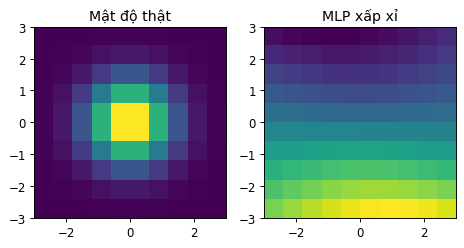

In [4]:
model = gaussian_trial(800, 16, 100, "gauss")
xy, truth = gaussian_grid(10).tensors
with torch.inference_mode():
    predicted = model(xy.to(DEVICE)).cpu()
fig, axes = plt.subplots(1, 2)
for ax, z, title in zip(axes, [truth, predicted], ["Mật độ thật", "MLP xấp xỉ"]):
    ax.imshow(z.reshape(10, 10), extent=(-3, 3, -3, 3), origin="lower")
    ax.set_title(title)
plt.show()
if FULL:
    for label, values in [("A", range(100, 1001, 100)), ("B", [8, 16, 32, 64, 128, 256, 512]), ("C", range(10, 200, 10))]:
        train_mse, test_mse = [], []
        for v in values:
            a, b, c = {"A": (v, 16, 100), "B": (800, v, 100), "C": (800, 128, v)}[label]
            key = f"{label}={v}"
            trial = gaussian_trial(a, b, c, key)
            grid_loss, _ = epoch(trial, DataLoader(gaussian_grid(32), 128), nn.MSELoss())
            train_mse.append(grid_loss)
            test_mse.append(results[key][3])
        plt.plot(values, train_mse, label="train")
        plt.plot(values, test_mse, label="test")
        plt.xlabel(label)
        plt.ylabel("MSE")
        plt.legend()
        plt.show()